# Saliency Maps Notebook

---

This notebook contains interactive examples on how to create saliency maps. This will be done using two methods:

1. **Deep Learning**
2. **Algorithmically**:  using handcrafted frequency and contrast statistics

---

In [16]:
#IMPORTS
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from abc import ABC, abstractmethod
#from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor


#CONSTANTS
image_paths = [
        "../images/test_images/driver_perspective_1.jpg",
        "../images/test_images/car_on_road.jpg",
        "../images/test_images/AC_car_bonnet_perspective.jpg",
        "../images/test_images/AC_driver_perspective_1.jpg",
        "../images/test_images/AC_driver_perspective_2.jpg",
        "../images/test_images/AC_dallara_perspective.png",
]

---

## Option 1: Deep Learning Approach

[INFO] Loading Driving Perception Model on: cpu


Loading weights: 100%|██████████| 208/208 [00:00<00:00, 10945.41it/s]


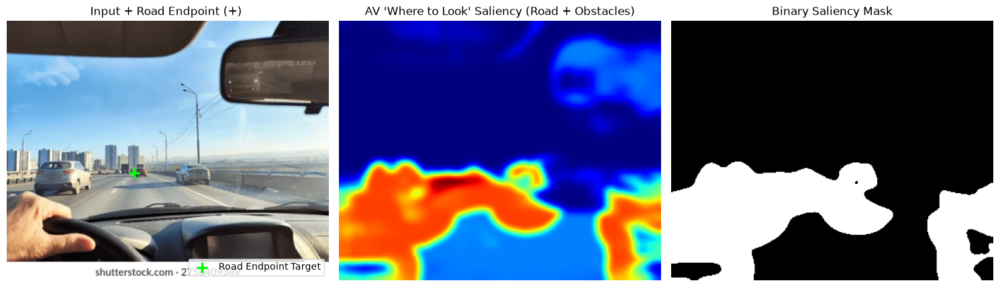

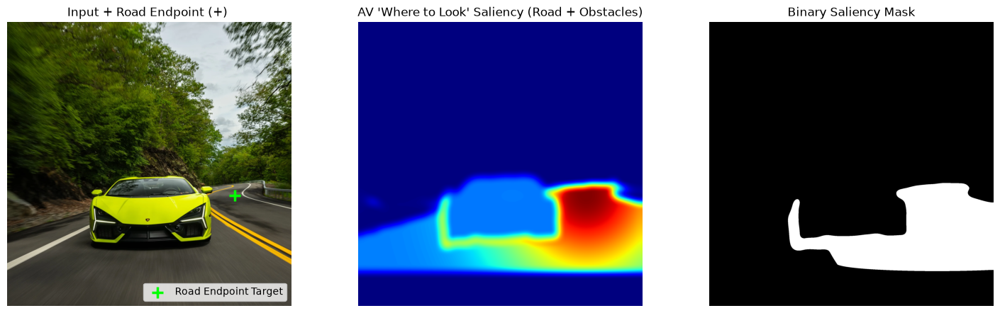

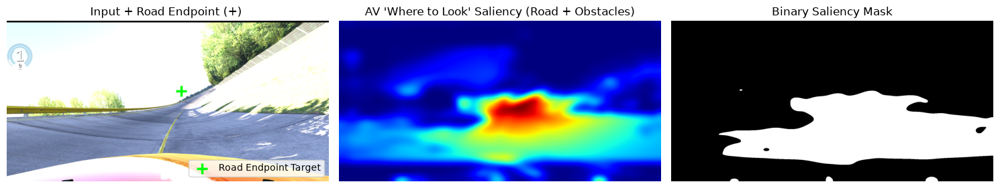

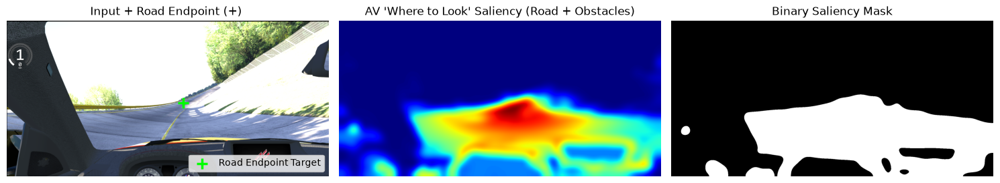

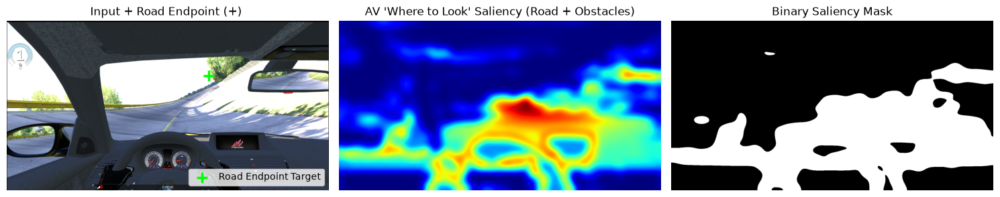

In [4]:
class AVWhereToLookSaliency:
    """Computes an active-vision 'Where to Look' saliency map for an AV on GPU

    by combining the drivable road's look-ahead endpoint with obstacle saliency.
    """

    # Cityscapes class indices
    ROAD_CLASS = 0
    # 11: person, 12: rider, 13: car, 14: truck, 15: bus, 17: motorcycle, 18: bicycle
    OBSTACLE_CLASSES = [11, 12, 13, 14, 15, 17, 18]
    # 6: traffic light, 7: traffic sign
    TRAFFIC_CONTROL_CLASSES = [6, 7]

    def __init__(
        self,
        model_name: str = "nvidia/segformer-b1-finetuned-cityscapes-1024-1024",
    ):
        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )
        print(f"[INFO] Loading Driving Perception Model on: {self.device}")

        self.processor = SegformerImageProcessor.from_pretrained(model_name)
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            model_name
        ).to(self.device)
        self.model.eval()

    @staticmethod
    def _compute_road_lookahead(
        road_prob: np.ndarray, road_mask: np.ndarray
    ) -> tuple[np.ndarray, tuple[int, int]]:
        """Finds the furthest look-ahead point (road endpoint / curve apex)

        and weights the drivable road toward that navigational target.
        """
        h, w = road_prob.shape
        ys, xs = np.where(road_mask > 0.5)

        if len(ys) == 0:
            # Fallback to horizon center if road is occluded
            target_y, target_x = int(h * 0.48), int(w * 0.5)
        else:
            # Find the top 5% furthest (highest in image, smallest y) road pixels
            furthest_cutoff = np.percentile(ys, 5)
            top_road_indices = ys <= furthest_cutoff
            target_y = int(np.mean(ys[top_road_indices]))
            target_x = int(np.mean(xs[top_road_indices]))

        # Create a 2D Gaussian look-ahead spotlight centered on the road endpoint
        y_grid, x_grid = np.ogrid[:h, :w]
        sigma_x = 0.22 * w
        sigma_y = 0.22 * h
        lookahead_gaussian = np.exp(
            -(
                ((x_grid - target_x) ** 2) / (2 * sigma_x**2)
                + ((y_grid - target_y) ** 2) / (2 * sigma_y**2)
            )
        )

        # Multiply road probability by the look-ahead spotlight
        # ( keeps attention on the drivable path leading to the apex/endpoint )
        nav_road_saliency = road_prob * (0.25 + 0.75 * lookahead_gaussian)

        # Suppress the bottom 12% right in front of the hood
        hood_fade = np.ones((h, w), dtype=np.float32)
        hood_fade[int(h * 0.88) :, :] = 0.0
        nav_road_saliency *= hood_fade

        max_v = np.max(nav_road_saliency)
        if max_v > 0:
            nav_road_saliency /= max_v

        return nav_road_saliency, (target_x, target_y)

    def generate(
        self,
        image_path: str,
        road_weight: float = 0.55,
        obstacle_weight: float = 0.45,
        cmap: str = "jet",
        show_plot: bool = True,
    ) -> dict:
        orig_pil = Image.open(image_path).convert("RGB")
        orig_w, orig_h = orig_pil.size
        orig_rgb = np.array(orig_pil)

        # 1. GPU Forward Pass
        inputs = self.processor(images=orig_pil, return_tensors="pt").to(
            self.device
        )
        with torch.no_grad():
            outputs = self.model(**inputs)
            # Upsample logits to original image size
            logits = F.interpolate(
                outputs.logits,
                size=(orig_h, orig_w),
                mode="bilinear",
                align_corners=False,
            )
            probs = torch.softmax(logits, dim=1).squeeze(0)  # [19, H, W]
            pred_classes = torch.argmax(probs, dim=0)        # [H, W]

        # 2. Extract Drivable Road & Look-Ahead Endpoint
        road_prob = probs[self.ROAD_CLASS].cpu().numpy()
        road_mask = (pred_classes == self.ROAD_CLASS).float().cpu().numpy()
        road_saliency, (aim_x, aim_y) = self._compute_road_lookahead(
            road_prob, road_mask
        )

        # 3. Extract Obstacles (Vehicles, Pedestrians, Cyclists) & Traffic Signs
        obstacle_tensor = torch.zeros((orig_h, orig_w), device=self.device)
        for cls_idx in self.OBSTACLE_CLASSES:
            obstacle_tensor += probs[cls_idx]
        for cls_idx in self.TRAFFIC_CONTROL_CLASSES:
            obstacle_tensor += 0.5 * probs[cls_idx]

        obstacle_map = torch.clamp(obstacle_tensor, 0.0, 1.0).cpu().numpy()

        # Dilate road mask slightly to prioritize obstacles that are ON or NEAR the road
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
        road_corridor = cv2.dilate(road_mask, kernel, iterations=2)
        obstacle_saliency = obstacle_map * (0.3 + 0.7 * road_corridor)

        # 4. Fuse "Where to Drive" (Road Endpoint) + "What to Avoid" (Obstacles)
        fused = (road_weight * road_saliency) + (
            obstacle_weight * obstacle_saliency
        )

        # Smooth into continuous fixation heatmap
        ksize = int(max(orig_h, orig_w) * 0.05) | 1
        sigma = ksize / 4.0
        fused_smooth = cv2.GaussianBlur(
            fused.astype(np.float32), (ksize, ksize), sigmaX=sigma, sigmaY=sigma
        )

        # Normalize to 0-255 uint8
        min_v, max_v = np.min(fused_smooth), np.max(fused_smooth)
        saliency_norm = (
            (fused_smooth - min_v) / (max_v - min_v)
            if max_v > min_v
            else np.zeros_like(fused_smooth)
        )
        saliency_map = (saliency_norm * 255).astype(np.uint8)

        # 5. Binary Saliency Mask via Otsu's Thresholding
        _, thresh_map = cv2.threshold(
            saliency_map, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU
        )

        # 6. Visualization (3-Panel Format + Aiming Point Overlay)
        if show_plot:
            fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

            axes[0].imshow(orig_rgb)
            axes[0].scatter(
                [aim_x],
                [aim_y],
                c="lime",
                s=120,
                marker="+",
                linewidths=2.5,
                label="Road Endpoint Target",
            )
            axes[0].set_title("Input + Road Endpoint (+) ")
            axes[0].legend(loc="lower right")
            axes[0].axis("off")

            axes[1].imshow(saliency_map, cmap=cmap)
            axes[1].set_title("AV 'Where to Look' Saliency (Road + Obstacles)")
            axes[1].axis("off")

            axes[2].imshow(thresh_map, cmap="gray")
            axes[2].set_title("Binary Saliency Mask")
            axes[2].axis("off")

            plt.tight_layout()
            plt.show()

        return {
            "InfoImage": saliency_map,
            "ThreshImage": thresh_map,
            "RoadSaliency": (road_saliency * 255).astype(np.uint8),
            "ObstacleSaliency": (obstacle_saliency * 255).astype(np.uint8),
            "LookAheadPoint": (aim_x, aim_y),
        }


if __name__ == "__main__":
    av_saliency = AVWhereToLookSaliency()

    image_paths = [
        "Images/driver_perspective_1.jpg",
        "Images/car_on_road.jpg",
        "Images/AC_car_bonnet_perspective.jpg",
        "Images/AC_driver_perspective_1.jpg",
        "Images/AC_driver_perspective_2.jpg"
    ]

    for path in image_paths:
        try:
            res = av_saliency.generate(
                image_path=path,
                road_weight=0.55,      # Balance between road trajectory and obstacles
                obstacle_weight=0.45,
                cmap="jet",            # Use "gray" for grayscale InfoImage
            )
        except FileNotFoundError as e:
            print(e)

## Option 2: Algorithmically Crafted

The core algorithm for this is called ***Spectral Residual Saliency***:

> In nature, standard background scenes (sky, grass, roads, and walls) share very predictable, repetitive patterns in the frequency domain. If an image is broken down into its spatial frequencies, the natural background follows an exponential power decay curve (often referred to as 1/f noise or the "scale invariance" of natural images).
>
>An "unexpected", salient background object acts as an "anomaly" or a spike that breaks the background pattern. The algorithm isolates this anomaly.

This is done through:

1. **Fourier Transform (FFT)**: The image is transformed into the frequency domain, extracting both its ***amplitude spectrum*** (i.e. how much each frequency exists) and its ***phase spectrum*** (i.e. where those frequencies spatially align). 

2. **Log Spectrum**: It computes the logarithm of the amplitude spectrum to compress wide dynamic ranges

3. **Average Curve (Redundant Background)**: It filters the log spectrum with an averaging box filter. This smoothed spectrum represents the "predictable/redundant background"

4. **Spectral Residual (The Anomaly)**: It subtracts the smoothed average spectrum from the original log spectrum:

    ### $$ \text{Residual} = \text{Log Amplitude} -  \text{Smoothed Log Amplitude} $$

    The background trend cancels out, leaving behind only the anomalies that break the pattern. 

5. **Inverse FFT (Spatial Saliency Map)**: The algorithm recombines this residual with the original phase spectrum and performs an Inverse Fourier Transform back into the spatial image domain. Squaring and smoothing the result yields a gray-scale map where rare, visually unexpected structures light up brightly


The output saliency map contains continuous floating-point values between 0.0 (background) and 1.0 (most salient foreground). This is achieved through an `Otsu Threshold` (as seen in the `thresh_map` section):

- Converts the continuous, soft heatmap into a hard binary mask (pure black 0 for background, pure white 255 for the salient objects/points)

- Normally, manually selecting a cut-off point (e.g. saliency > 128) fails across varying images because lighting, contrast, and foreground sizes vary wildly

    - Instead, Otsu's algorithm automatically searches through all 256 possible intensity thresholds. It finds the exact threshold that minimises the intra-class variance (i.e. the spread of intensities within the foreground and background groups) while maximising the inter-class variance (i.e. the separation between the two groups)

- The output is a `thresh_map`, a binary foreground segmentation proposal, without requiring any manual hyperparameter tuning  

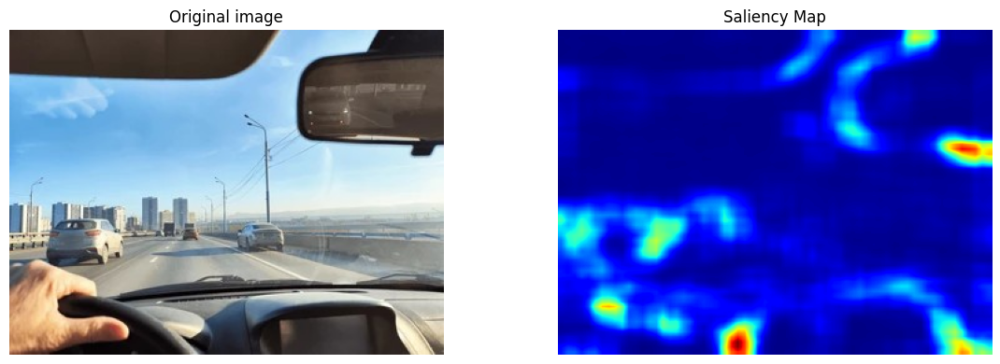

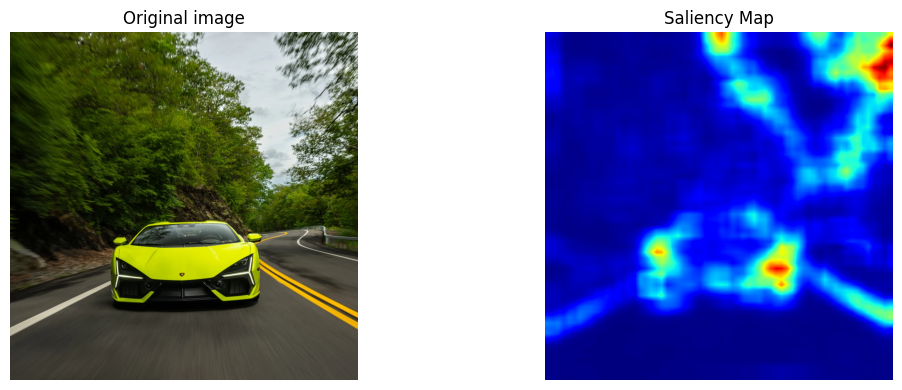

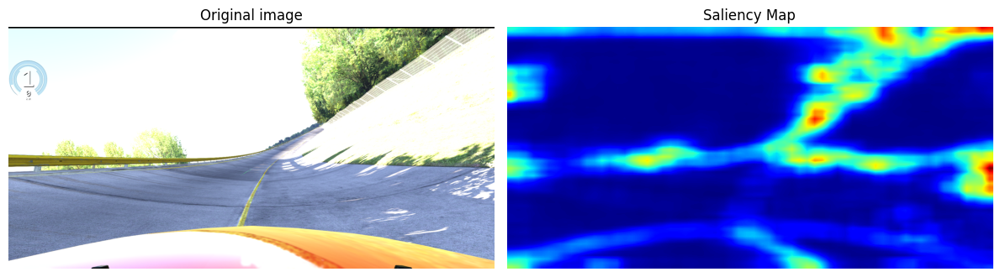

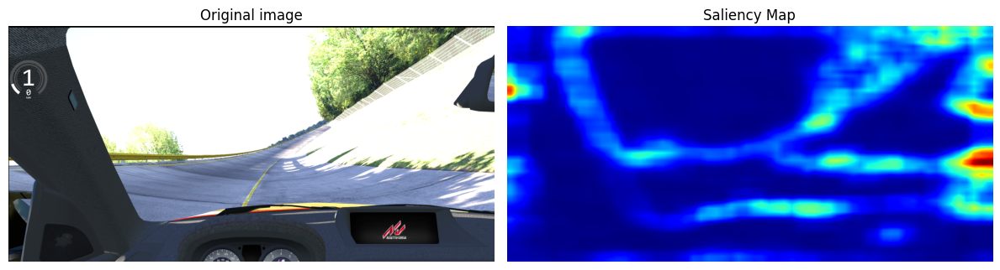

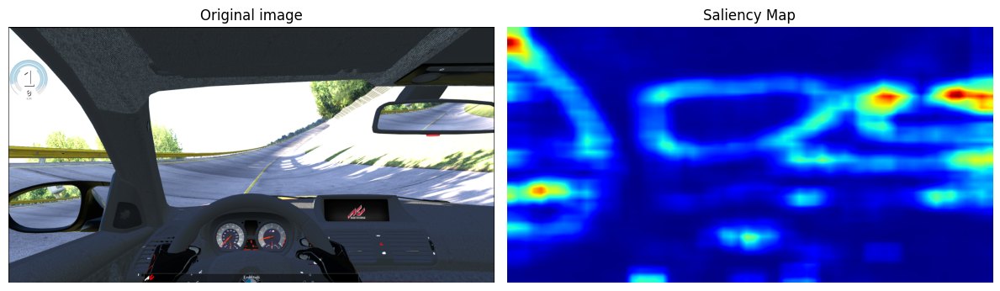

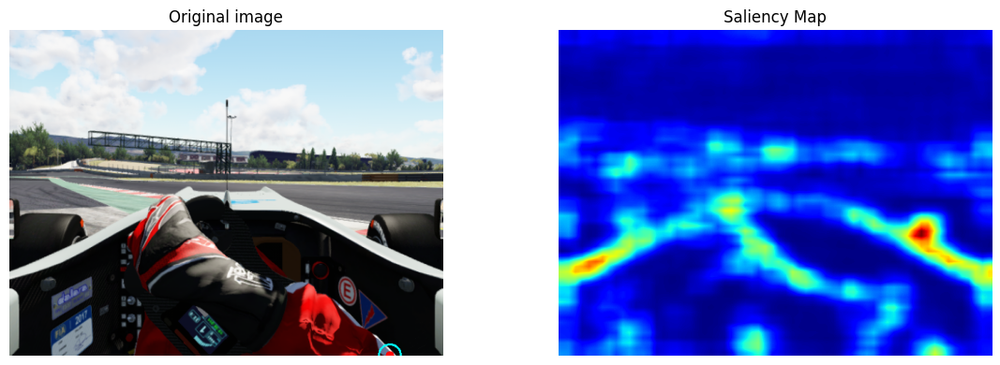

In [ ]:
def detect_visual_saliency(image_path: str):

    # Reads the image in as a multi-channel numpy array in BGR format
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(f"Could not find image path: {image_path}")

    #Initialise OpenCV Static Saliency Spectral Residual (SSSR) detector
    saliency = cv2.saliency.StaticSaliencySpectralResidual_create()
    success, saliency_map = saliency.computeSaliency(image)

    #Convert to the floating point values [0.0, 1.0] into an 8-bit integer range [0, 255] 
    # where 0 = pure black and 255 = peak intensity (this range is chosen as the opencv tools work within the 8-bit range)
    saliency_map = (saliency_map * 255).astype("uint8")

    # Optional: Binarise the map using Otsu's thresholding - Query this
    # _, thresh_map = cv2.threshold(saliency_map, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    #Plot the results
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # fig, axes = plt.subplots(1,3, figsize = (12, 4))
    fig, axes = plt.subplots(1,2, figsize = (12, 4))

    axes[0].imshow(image_rgb)
    axes[0].set_title("Original image")
    axes[0].axis("off")

    axes[1].imshow(saliency_map, cmap="jet")
    axes[1].set_title("Saliency Map")
    axes[1].axis("off")

    # axes[2].imshow(thresh_map, cmap = "gray")
    # axes[2].set_title("Binary Saliency")
    # axes[2].axis("off")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":

    for path in image_paths:
        detect_visual_saliency(path)
    


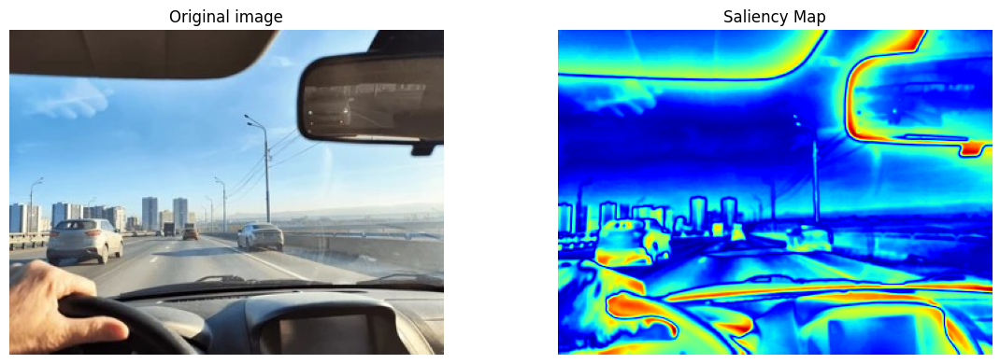

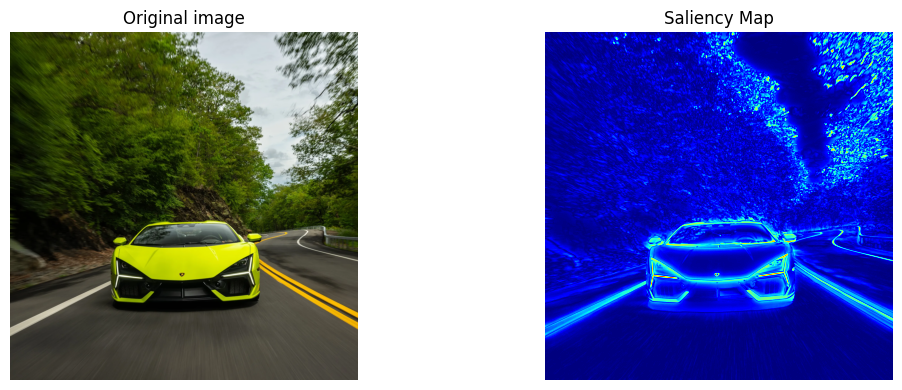

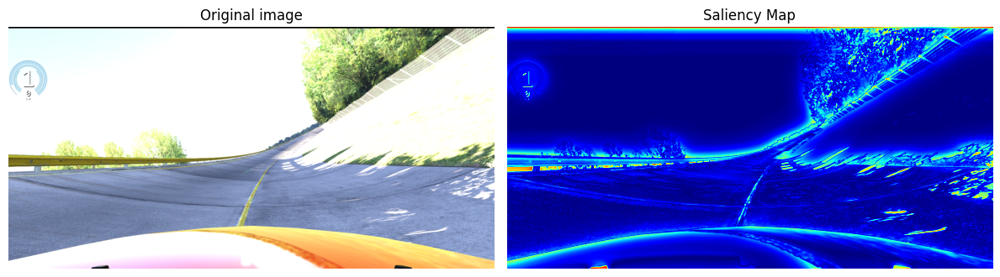

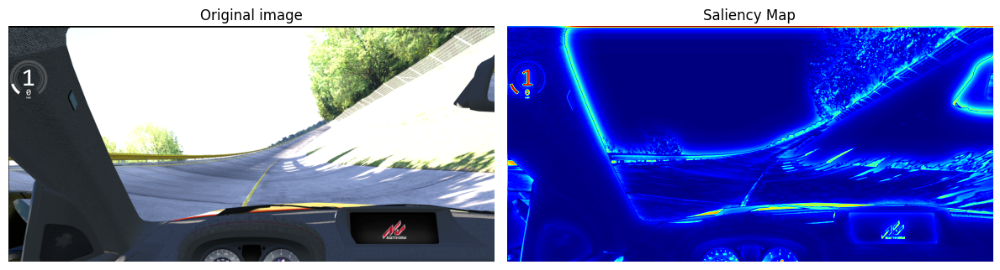

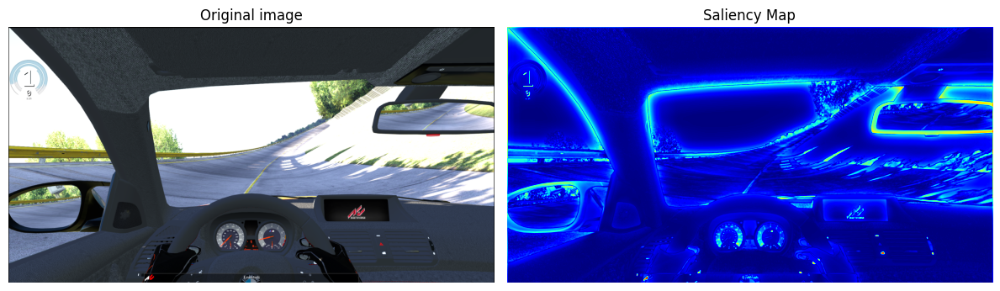

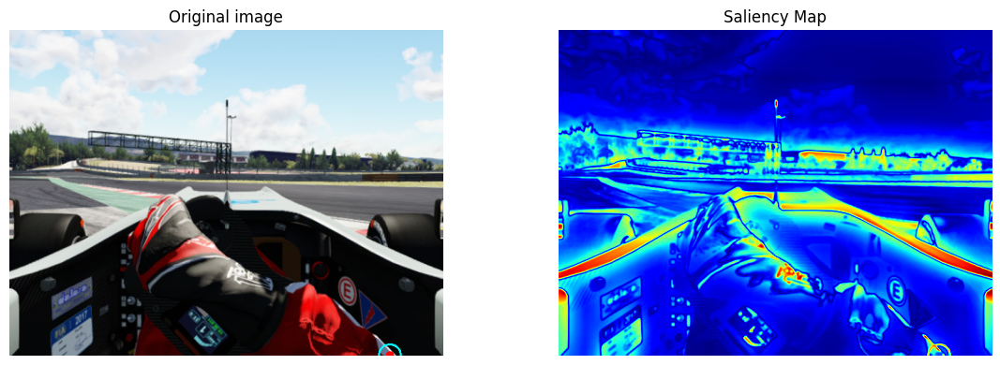

In [22]:
class BaseSaliencyEngine(ABC):
    
    @abstractmethod
    def compute_heatmap(self, img_bgr: np.ndarray) -> np.ndarray:
        
        """Calculates normalized 2D heatmap in range [0.0, 1.0]"""
        pass


    def get_peak_salient_point(self, heatmap: np.ndarray) -> tuple[int, int]:
        
        """
        Default peak point finder (argmax). Can be overridden if needed.
        Finds the most salient point, represented in (x, y); where (x, y) = argmax S(x, y)
        """
        _, _, _, max_loc = cv2.minMaxLoc(heatmap)
        return max_loc  # returns (x, y)


class FineGrainedSaliencyEngine(BaseSaliencyEngine):
    
    def __init__(self):
        self.saliency = cv2.saliency.StaticSaliencyFineGrained_create()


    def compute_heatmap(self, img_bgr: np.ndarray) -> np.ndarray:
        
        success, heatmap = self.saliency.computeSaliency(img_bgr)
        
        if not success:
            return np.zeros(img_bgr.shape[:2], dtype=np.float32)
        
        # Normalize to [0, 1]
        min_v, max_v = np.min(heatmap), np.max(heatmap)
        return (heatmap - min_v) / (max_v - min_v + 1e-8)
    
    
def detect_visual_saliency(image_path: str, saliency_engine):

    # Reads the image in as a multi-channel numpy array in BGR format
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(f"Could not find image path: {image_path}")

    #Initialise OpenCV Static Saliency Spectral Residual (SSSR) detector
    saliency = saliency_engine.saliency #cv2.saliency.StaticSaliencySpectralResidual_create()
    success, saliency_map = saliency.computeSaliency(image)

    #Convert to the floating point values [0.0, 1.0] into an 8-bit integer range [0, 255] 
    # where 0 = pure black and 255 = peak intensity (this range is chosen as the opencv tools work within the 8-bit range)
    saliency_map = (saliency_map * 255).astype("uint8")

    # Optional: Binarise the map using Otsu's thresholding - Query this
    # _, thresh_map = cv2.threshold(saliency_map, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    #Plot the results
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # fig, axes = plt.subplots(1,3, figsize = (12, 4))
    fig, axes = plt.subplots(1,2, figsize = (12, 4))

    axes[0].imshow(image_rgb)
    axes[0].set_title("Original image")
    axes[0].axis("off")

    axes[1].imshow(saliency_map, cmap="jet")
    axes[1].set_title("Saliency Map")
    axes[1].axis("off")

    # axes[2].imshow(thresh_map, cmap = "gray")
    # axes[2].set_title("Binary Saliency")
    # axes[2].axis("off")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    
    fine_grain = FineGrainedSaliencyEngine()
    

    for path in image_paths:
        detect_visual_saliency(path, fine_grain)
    


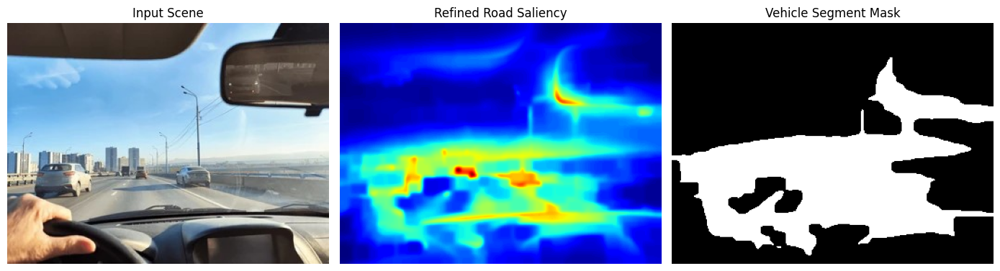

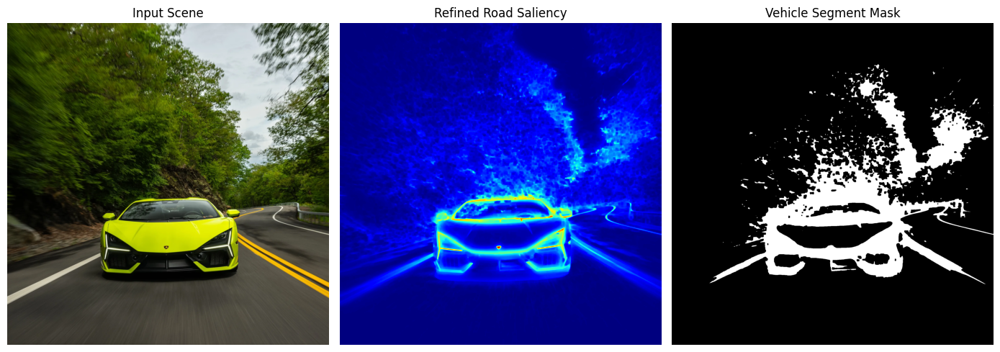

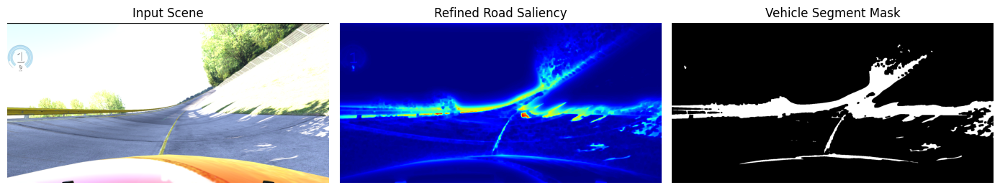

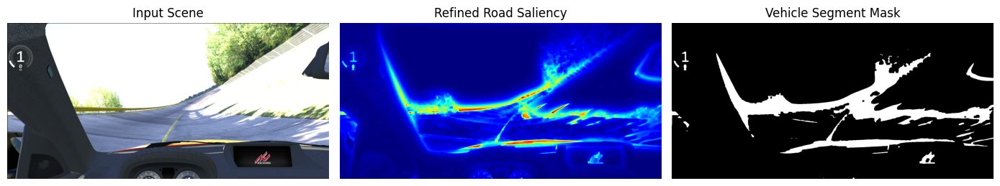

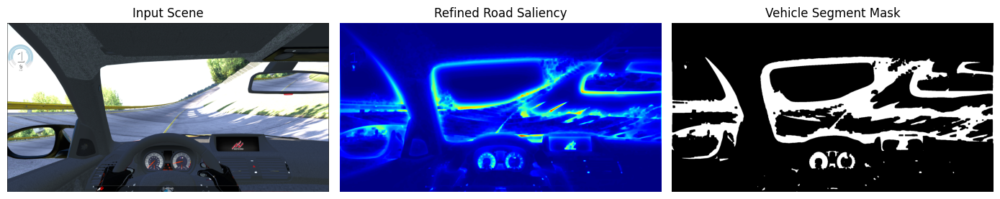

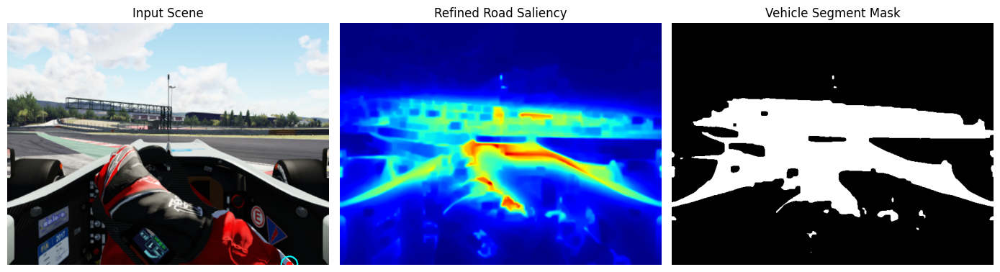

In [23]:
def process_road_scene_saliency(image_path: str):
    
    image = cv2.imread(image_path)
    
    if image is None:
        raise FileNotFoundError(f"Image not found at {image_path}")

    #Fine-grained saliency
    fine_saliency = cv2.saliency.StaticSaliencyFineGrained_create()
    _, sal_map = fine_saliency.computeSaliency(image)
    sal_map = (sal_map * 255).astype("uint8")

    #Road prior (suppress top sky & peripheral noise)
    h, w = sal_map.shape
    y, x = np.ogrid[:h, :w]
    
    center_y, center_x = int(h * 0.55), int(w * 0.5)
    gauss_prior = np.exp(-(((x - center_x) ** 2) / (2 * (w * 0.35) ** 2) + 
                           ((y - center_y) ** 2) / (2 * (h * 0.25) ** 2)))
    
    prior_map = (sal_map * gauss_prior).astype("uint8")

    #Morphological closing to fuse car boundaries into solid objects
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (11, 11))
    fused_map = cv2.morphologyEx(prior_map, cv2.MORPH_CLOSE, kernel)
    fused_map = cv2.GaussianBlur(fused_map, (9, 9), 0)

    #Otsu Thresholding
    _, thresh_map = cv2.threshold(fused_map, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    #Display
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Input Scene")
    axes[0].axis("off")

    axes[1].imshow(fused_map, cmap="jet")
    axes[1].set_title("Refined Road Saliency")
    axes[1].axis("off")

    axes[2].imshow(thresh_map, cmap="gray")
    axes[2].set_title("Vehicle Segment Mask")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":

    for image in image_paths: 
        process_road_scene_saliency(image)

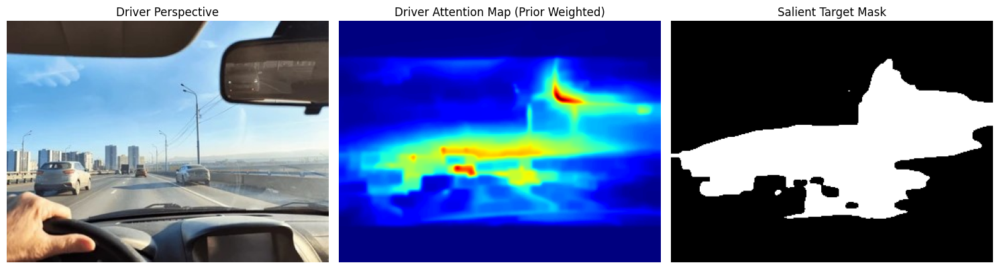

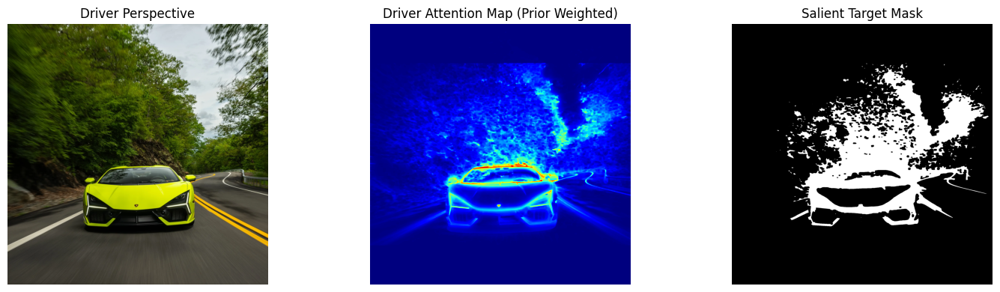

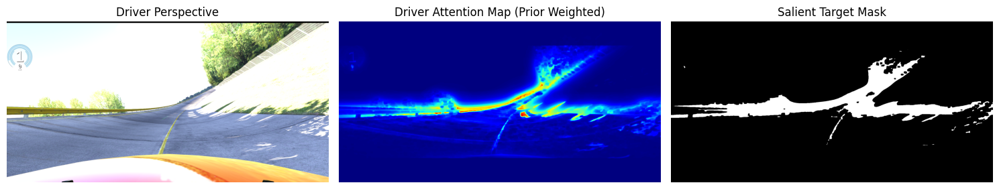

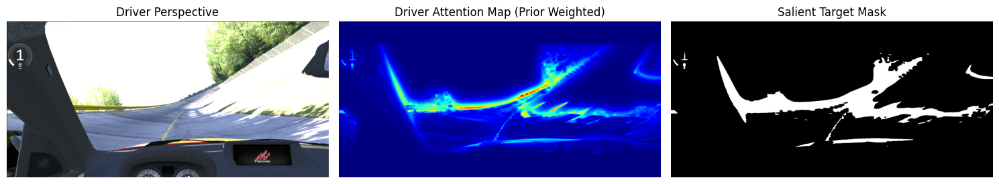

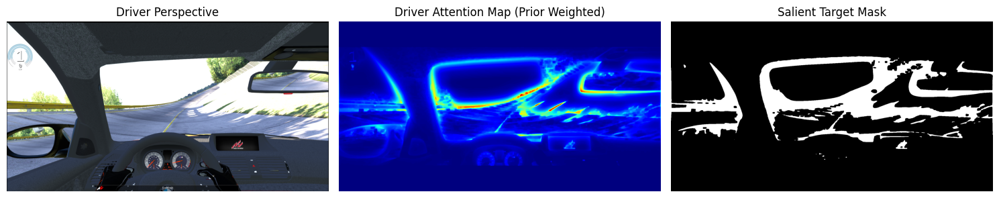

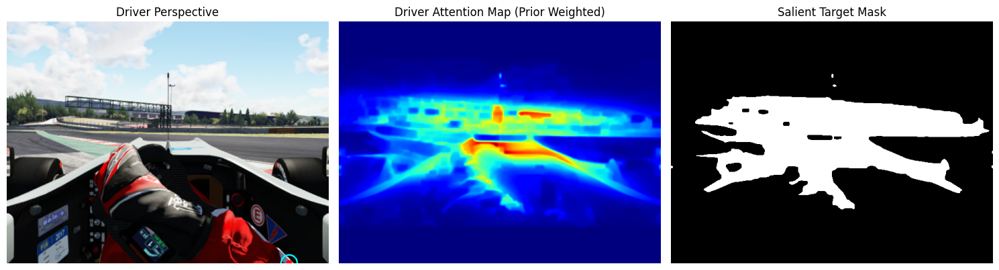

In [24]:
def driver_perspective_saliency(image_path: str):
    
    image = cv2.imread(image_path)
    
    if image is None:
        raise FileNotFoundError(f"Image not found at {image_path}")

    h, w = image.shape[:2]

    #Use Fine-Grained Saliency (preserves sharp object boundaries better than Spectral Residual)
    saliency_engine = cv2.saliency.StaticSaliencyFineGrained_create()
    _, sal_map = saliency_engine.computeSaliency(image)
    sal_map = (sal_map * 255).astype("uint8")

    #Construct Driver Gaze Prior (Centered horizontally, anchored near the horizon)
    # The horizon for standard dashcams typically rests around 45% - 55% of the frame height
    horizon_y = int(h * 0.48)
    center_x = int(w * 0.50)

    y, x = np.ogrid[:h, :w]
    # Drivers scan horizontally along the road plane, so use wider horizontal sigma (sigma_x > sigma_y)
    sigma_x = 0.30 * w
    sigma_y = 0.18 * h
    driver_prior = np.exp(-(((x - center_x) ** 2) / (2 * sigma_x ** 2) + 
                            ((y - horizon_y) ** 2) / (2 * sigma_y ** 2)))

    # 3. Explicit Mask: Eliminate own-vehicle hood/dashboard (bottom 15%) & extreme upper sky (top 15%)
    fov_mask = np.ones((h, w), dtype=np.float32)
    fov_mask[int(h * 0.85):, :] = 0.0  # Mask out car hood / dashboard
    fov_mask[:int(h * 0.15), :] = 0.1  # Suppress upper sky

    #Combine prior with raw saliency
    weighted_saliency = sal_map.astype(np.float32) * driver_prior * fov_mask
    weighted_saliency = cv2.normalize(weighted_saliency, None, 0, 255, cv2.NORM_MINMAX).astype("uint8")

    #Morphological Filtering to bridge broken car chassis & suppress thin lane markings
    # Rectangular kernel bridges vehicle chassis while absorbing dashed lane noise
    car_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 9))
    closed_map = cv2.morphologyEx(weighted_saliency, cv2.MORPH_CLOSE, car_kernel)
    final_saliency = cv2.GaussianBlur(closed_map, (9, 9), 0)

    #Otsu Threshold for salient vehicle segmentation
    _, binary_mask = cv2.threshold(final_saliency, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    # Visualisation
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Driver Perspective")
    axes[0].axis("off")

    axes[1].imshow(final_saliency, cmap="jet")
    axes[1].set_title("Driver Attention Map (Prior Weighted)")
    axes[1].axis("off")

    axes[2].imshow(binary_mask, cmap="gray")
    axes[2].set_title("Salient Target Mask")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    
    for image in image_paths:
        driver_perspective_saliency(image)
    
    
    

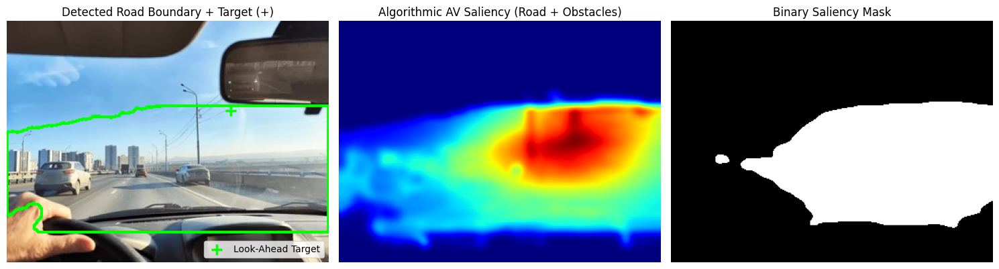

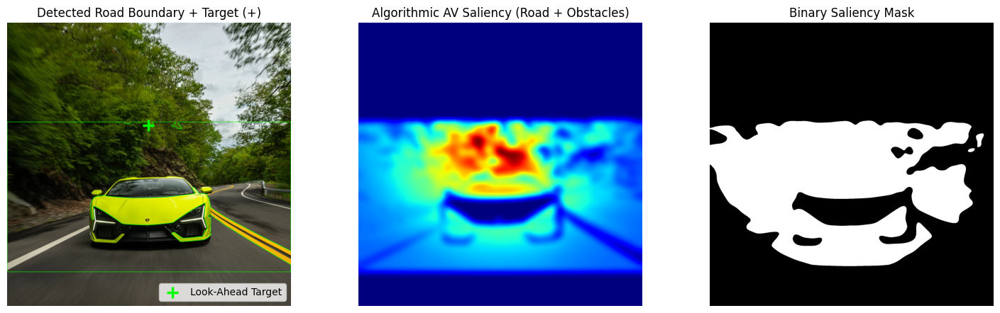

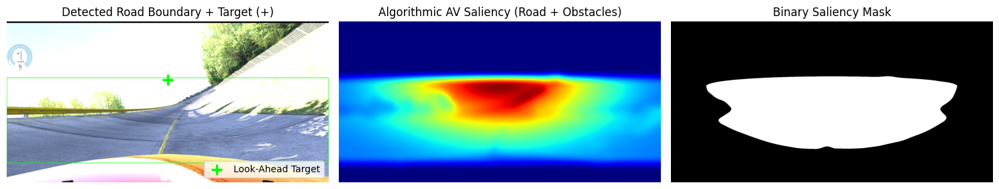

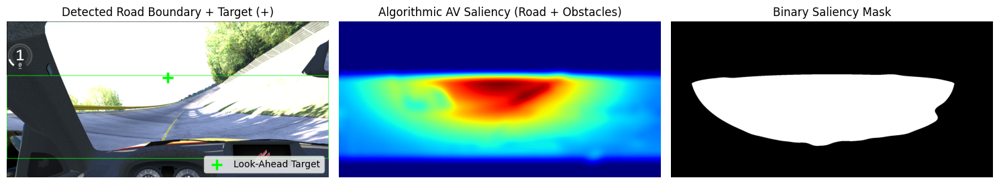

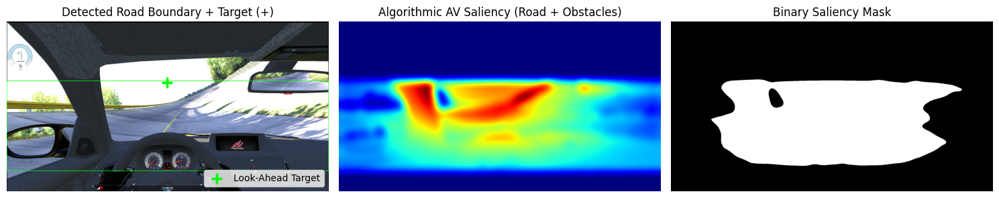

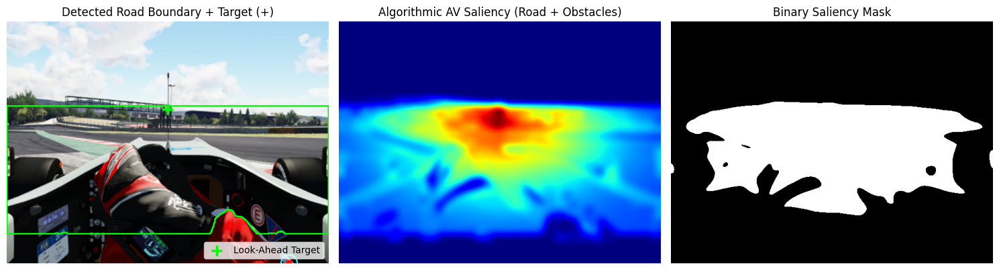

In [25]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def compute_fine_grained_contrast(img_bgr: np.ndarray) -> np.ndarray:
    """Computes multi-scale center-surround visual contrast natively in CIE LAB

    space without requiring opencv-contrib-python (cv2.saliency).
    """
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2Lab).astype(np.float32)
    fine = cv2.GaussianBlur(lab, (3, 3), 0)

    contrast_map = np.zeros(img_bgr.shape[:2], dtype=np.float32)

    # Compare fine center pixels against local surround neighborhoods across 3 scales
    for ksize in (9, 19, 35):
        surround = cv2.GaussianBlur(lab, (ksize, ksize), 0)
        diff = np.sqrt(np.sum((fine - surround) ** 2, axis=2))
        contrast_map += diff

    max_v = np.max(contrast_map)
    return contrast_map / max_v if max_v > 0 else contrast_map


def segment_road_from_seed(
    img_bgr: np.ndarray,
    seed_y_range: tuple = (0.72, 0.85),
    seed_x_range: tuple = (0.40, 0.60),
    color_tol: float = 2.5,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    
    """
    Segments the drivable road surface by sampling a bottom-center seed patch
    in CIE LAB space and extracting the largest connected component.
    """
    h, w = img_bgr.shape[:2]

    blurred = cv2.GaussianBlur(img_bgr, (7, 7), 0)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2Lab).astype(np.float32)

    #Extract statistics from the bottom-center road seed box
    y1, y2 = int(h * seed_y_range[0]), int(h * seed_y_range[1])
    x1, x2 = int(w * seed_x_range[0]), int(w * seed_x_range[1])
    seed_patch = lab[y1:y2, x1:x2]

    mean_lab = np.mean(seed_patch, axis=(0, 1))
    std_lab = np.std(seed_patch, axis=(0, 1)) + 5.0

    #Weight chromaticity (A, B) higher than luminance (L) to handle road shadows
    weights = np.array([0.4, 1.2, 1.2], dtype=np.float32)
    dist = np.sqrt(
        np.sum(weights * ((lab - mean_lab) / (std_lab * color_tol)) ** 2, axis=2)
    )

    road_prob = np.exp(-0.5 * (dist**2))

    #Suppress upper sky (top 35%) and ego-hood (bottom 12%)
    road_prob[: int(h * 0.35), :] = 0.0
    road_prob[int(h * 0.88) :, :] = 0.0

    #Binarise and keep the connected component attached to the bottom-center seed
    raw_mask = (road_prob > 0.35).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    raw_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, _, _ = cv2.connectedComponentsWithStats(raw_mask)
    road_mask = np.zeros((h, w), dtype=np.float32)
    road_corridor = np.zeros((h, w), dtype=np.float32)

    seed_labels = labels[y1:y2, x1:x2]
    valid_labels = seed_labels[seed_labels > 0]

    if len(valid_labels) > 0:
        road_label = np.bincount(valid_labels).argmax()
        road_mask = (labels == road_label).astype(np.float32)

        # Convex hull bridges over obstacles sitting inside the road lane
        contours, _ = cv2.findContours(
            (road_mask * 255).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE,
        )
        if contours:
            largest_cnt = max(contours, key=cv2.contourArea)
            hull = cv2.convexHull(largest_cnt)
            cv2.drawContours(
                road_corridor, [hull], -1, 1.0, thickness=cv2.FILLED
            )
            road_corridor = cv2.dilate(road_corridor, kernel, iterations=2)
            
    else:
        #Fallback trapezoid corridor if seed is occluded
        road_corridor[int(h * 0.40) : int(h * 0.88), :] = 1.0

    return road_prob * road_mask, road_mask, road_corridor


def compute_lookahead_saliency(road_prob: np.ndarray, road_mask: np.ndarray) -> tuple[np.ndarray, tuple[int, int]]:
    
    """
    Finds the furthest visible point of the road (endpoint / curve apex)
    and weights the road mask toward that target.
    """
    
    h, w = road_prob.shape
    ys, xs = np.where(road_mask > 0.5)

    if len(ys) == 0:
        aim_y, aim_x = int(h * 0.48), int(w * 0.50)
        
    else:
        cutoff_y = np.percentile(ys, 5)
        apex_pts = ys <= cutoff_y
        aim_y = int(np.mean(ys[apex_pts]))
        aim_x = int(np.mean(xs[apex_pts]))

    y_grid, x_grid = np.ogrid[:h, :w]
    sigma_x, sigma_y = 0.22 * w, 0.22 * h
    spotlight = np.exp(
        -(
            ((x_grid - aim_x) ** 2) / (2 * sigma_x**2)
            + ((y_grid - aim_y) ** 2) / (2 * sigma_y**2)
        )
    )

    lookahead_map = road_prob * (0.2 + 0.8 * spotlight)
    max_v = np.max(lookahead_map)
    
    if max_v > 0:
        lookahead_map /= max_v

    return lookahead_map, (aim_x, aim_y)


def compute_obstacle_saliency(img_bgr: np.ndarray, road_mask: np.ndarray, road_corridor: np.ndarray) -> np.ndarray:
    
    """
    Detects obstacles as high-contrast, high-edge anomalies inside or
    bordering the drivable road corridor that do not match the asphalt.
    """
    
    #Native multi-scale center-surround visual contrast
    contrast_map = compute_fine_grained_contrast(img_bgr)

    #Vertical & horizontal edge energy
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    sobel_x = np.abs(cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3))
    
    sobel_y = np.abs(cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3))
    edge_energy = cv2.GaussianBlur(sobel_x + 0.5 * sobel_y, (15, 15), 0)
    
    if np.max(edge_energy) > 0:
        edge_energy /= np.max(edge_energy)

    #Non-road anomaly inside the road's convex hull corridor
    non_road_in_corridor = np.clip(road_corridor - (road_mask * 0.65), 0.0, 1.0)

    obstacle_map = contrast_map * edge_energy * non_road_in_corridor

    #Close gaps inside vehicle bodies
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    obstacle_map = cv2.morphologyEx(obstacle_map, cv2.MORPH_CLOSE, kernel)

    max_v = np.max(obstacle_map)
    
    if max_v > 0:
        obstacle_map /= max_v

    return obstacle_map


def generate_algorithmic_av_saliency(image_path: str, road_weight: float = 0.55, obstacle_weight: float = 0.45, cmap: str = "jet") -> dict:
    
    img_bgr = cv2.imread(image_path)
    
    if img_bgr is None:
        raise FileNotFoundError(f"Image not found at: {image_path}")

    h, w = img_bgr.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    #Segment road surface and road corridor from bottom-center seed
    road_prob, road_mask, road_corridor = segment_road_from_seed(img_bgr)

    #Compute "Where to Drive" look-ahead saliency & endpoint
    lookahead_saliency, (aim_x, aim_y) = compute_lookahead_saliency(
        road_prob, road_mask
    )

    #Compute Obstacle saliency inside the road corridor
    obstacle_saliency = compute_obstacle_saliency(
        img_bgr, road_mask, road_corridor
    )

    #Fuse & Smooth
    fused = (road_weight * lookahead_saliency) + (
        obstacle_weight * obstacle_saliency
    )
    ksize = int(max(h, w) * 0.05) | 1
    sigma = ksize / 4.0
    fused_smooth = cv2.GaussianBlur(
        fused.astype(np.float32), (ksize, ksize), sigmaX=sigma, sigmaY=sigma
    )

    #Normalise to 0-255 uint8 (for cv2 libraries)
    min_v, max_v = np.min(fused_smooth), np.max(fused_smooth)
    
    saliency_norm = (
        (fused_smooth - min_v) / (max_v - min_v)
        if max_v > min_v
        else np.zeros_like(fused_smooth)
    )
    
    saliency_map = (saliency_norm * 255).astype(np.uint8)

    #Discretise using adaptive threshold (1.5 * mean saliency)
    adaptive_thresh = int(np.clip(1.5 * np.mean(saliency_map), 0, 255))
    _, thresh_map = cv2.threshold(
        saliency_map, adaptive_thresh, 255, cv2.THRESH_BINARY
    )

    # Visualisation
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    debug_rgb = img_rgb.copy()
    road_cnts, _ = cv2.findContours(
        (road_mask * 255).astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )
    
    cv2.drawContours(debug_rgb, road_cnts, -1, (0, 255, 0), 2)

    axes[0].imshow(debug_rgb)
    axes[0].scatter(
        [aim_x],
        [aim_y],
        c="lime",
        s=140,
        marker="+",
        linewidths=2.5,
        label="Look-Ahead Target",
    )
    
    axes[0].set_title("Detected Road Boundary + Target (+)")
    axes[0].legend(loc="lower right")
    axes[0].axis("off")

    axes[1].imshow(saliency_map, cmap=cmap)
    axes[1].set_title("Algorithmic AV Saliency (Road + Obstacles)")
    axes[1].axis("off")

    axes[2].imshow(thresh_map, cmap="gray")
    axes[2].set_title("Binary Saliency Mask")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    return {
        "InfoImage": saliency_map,
        "ThreshImage": thresh_map,
        "RoadMask": (road_mask * 255).astype(np.uint8),
        "ObstacleSaliency": (obstacle_saliency * 255).astype(np.uint8),
        "LookAheadPoint": (aim_x, aim_y),
    }


if __name__ == "__main__":

    for path in image_paths:
        try:
            generate_algorithmic_av_saliency(path, cmap="jet")
        except FileNotFoundError as e:
            print(e)

| Feature | Option 1 (PyTorch / ResNet) | Option 2 (OpenCV Spectral Residual) |
| :--- | :--- | :--- |
| **Goal** | **Model interpretability**: Highlights pixels that the trained classifier focused on. | **Visual saliency**: Highlights regions that naturally grab human attention. |
| **Dependencies** | PyTorch, Pretrained weights (~100 MB). | OpenCV (`opencv-contrib-python`), lightweight. |
| **Speed** | Requires a neural forward/backward pass (best on GPU). | Runs in milliseconds on a standard CPU. |
| **Semantics** | Understands objects (e.g., faces, wheels, animals). | Relies purely on low-level patterns, contrast, and frequencies. |

### Research References

* **Simonyan, K., Vedaldi, A., & Zisserman, A. (2014).** *Deep inside convolutional networks: Visualising image classification models and saliency maps.* ICLR Workshop.  
  *(Formulates gradient-based class saliency via backpropagation of classification scores to input pixels).*
* **He, K., Zhang, X., Ren, S., & Sun, J. (2016).** *Deep residual learning for image recognition.* IEEE CVPR, pp. 770–778.  
  *(Introduces ResNet architectures and pretrained deep semantic feature hierarchies).*
* **Hou, X., & Zhang, L. (2007).** *Saliency detection: A spectral residual approach.* IEEE CVPR, pp. 1–8.  
  *(Establishes the frequency-domain log-spectrum residual model implemented in OpenCV's `StaticSaliencySpectralResidual`).*
* **Itti, L., & Koch, C. (2001).** *Computational modeling of visual attention.* Nature Reviews Neuroscience, 2(3), pp. 194–203.  
  *(Foundational theory on bottom-up visual attention driven by low-level contrast and feature maps).*
* **Borji, A., Sihite, D. N., & Itti, L. (2015).** *Salient object detection: A benchmark.* IEEE TIP, 24(12), pp. 5706–5722.  
  *(Comprehensive benchmark highlighting the differences between low-level heuristic priors and high-level deep representations).*